# Deep Field Mass Maps with shapeHSM

Using the `desc-stack-weekly` environment.

`python/shapehsm_create_maps.py` repeats this but parallelized.

Last ran on : October 28th, 2026

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp
import healsparse as hsp
import astropy.units as u
import skyproj
from astropy.coordinates import SkyCoord, angular_separation, position_angle
from astropy.io import fits
from astropy.table import Table, vstack
import scipy.stats as stats
import importlib
from matplotlib import cm

import os, gc, sys

%matplotlib inline
plt.rcParams.update({"font.size": 12})

In [3]:
sys.path.insert(1, '../python/')

In [4]:
import shapehsm_per_tract as spt
import schirmer_map_fns as smf

In [5]:
# importlib.reload(smf)
# importlib.reload(spt)

 - `shapehsm_per_tract` processes each tract indepenently to produce `g1`/`g2`/`weight`/`weight^2`, and `N_gal` maps using a 4096 Nside healsparse map.
 - `schirmer_map_fns` has the basic functionality to convert those maps into aperture maps

In [6]:
deep_field_tracts = {
       'ELAIS S1': [2535, 2536, 2702, 2703, 2704, 2705, 2875, 2876, 2877, 2878, 3052, 3053, 3054, 3055],
       'ECDFS': [4636, 4637, 4638, 4847, 4848, 4849, 4850, 5062, 5063, 5064, 5279, 5280, 5281],
       'COSMOS': [ 9569,  9570,  9571,  9572,  9812,  9813,  9814, 10054, 10055, 10056],
       'EDFS': [2078, 2079, 2080, 2233, 2234, 2235, 2236, 2237, 2393, 2394, 2395, 2396, 2397, 2558, 2559, 2560, 2561, 2562, 2729, 2730]
}

In [33]:
full_tracts = np.load('/pscratch/sd/p/pecom/dp2_footprints/tract_list.npy')

In [36]:
# Reading in pre-processed tracts but processing tracts is simply:
for ft in full_tracts:
    spt.process_tract(ft)

/opt/lsst/software/stack/conda/envs/lsst-scipipe-13.0.0/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:867: UserWarning: Warning: 'partition' will ignore the 'mask' of the MaskedColumn.
  a.partition(kth, axis=axis, kind=kind, order=order)
/global/u1/p/pecom/repos/dp2-clusters-shear-mapping/notebooks/../python/shapehsm_per_tract.py:146: RuntimeWarning: Mean of empty slice
  msmt_variance = np.nanmean(e1**2 + e2**2) / 2.0 - np.nanmedian(catalog['i_hsmShapeRegauss_sigma']**2)


In [8]:
# We can read and combine the maps for a field:

# Output directory is normally:
output_dir = '/global/cfs/cdirs/lsst/groups/CL/DP2/dp2_massmaps/hsp_maps'

g1s = []
g2s = []
ws = []
w2s = []
Ns = []

for tract in deep_field_tracts['COSMOS']:
    g1s.append(hsp.HealSparseMap.read(f'{output_dir}/shapeHSM_v0_{tract}_g1.hs'))
    g2s.append(hsp.HealSparseMap.read(f'{output_dir}/shapeHSM_v0_{tract}_g2.hs'))
    ws.append(hsp.HealSparseMap.read(f'{output_dir}/shapeHSM_v0_{tract}_w.hs'))
    w2s.append(hsp.HealSparseMap.read(f'{output_dir}/shapeHSM_v0_{tract}_w2.hs'))
    Ns.append(hsp.HealSparseMap.read(f'{output_dir}/shapeHSM_v0_{tract}_ngals.hs'))
    

In [ ]:
deepfield_g1.write

In [9]:
# Add together each tract. Since we are working on disjoint regions we want the union
# and don't need to worry about collisions over sums

deepfield_g1 = hsp.operations.sum_union(g1s)
deepfield_g2 = hsp.operations.sum_union(g2s)
deepfield_w = hsp.operations.sum_union(ws)
deepfield_w2 = hsp.operations.sum_union(w2s)
deepfield_N = hsp.operations.sum_union(Ns)

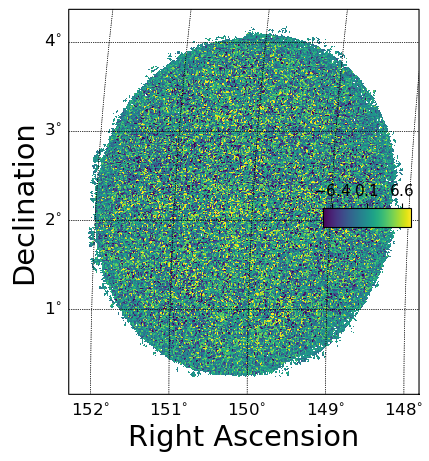

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
sp = skyproj.McBrydeSkyproj(ax=ax)
im, lon_raster, lat_raster, values_raster = sp.draw_hspmap(deepfield_g1)
sp.draw_inset_colorbar()
plt.show()

In [11]:
importlib.reload(smf)

<module 'schirmer_map_fns' from '/global/u1/p/pecom/repos/dp2-clusters-shear-mapping/notebooks/../python/schirmer_map_fns.py'>

In [12]:
# Convert the maps into the nice 1D lists
# that we can process

full_hp_coords, comp_g_hp, g_sqr_hp = smf.prep_hsp_maps(deepfield_g1,
                                                        deepfield_g2, 
                                                        deepfield_w,
                                                        deepfield_w2)

In [13]:
valid_pixs = deepfield_g1.valid_pixels

In [19]:
len(valid_pixs)

57860

In [14]:
# Calculate E/B/V using the 1D lists at the pixels requested.
# Passing in a list of pixels makes this easier to parallelize.
e_map, b_map, v_map = smf.process_maps(full_hp_coords, comp_g_hp, g_sqr_hp, valid_pixs[:2000])

/global/u1/p/pecom/repos/dp2-clusters-shear-mapping/notebooks/../python/schirmer_map_fns.py:36: RuntimeWarning: overflow encountered in exp
  Q =  1./(1. + np.exp(a-b*x) + np.exp(d*x-c) )
/global/u1/p/pecom/repos/dp2-clusters-shear-mapping/notebooks/../python/schirmer_map_fns.py:37: RuntimeWarning: invalid value encountered in divide
  Q *= np.tanh( x/xc ) / ( x/xc )


In [22]:
odir = '/global/cfs/cdirs/lsst/groups/CL/DP2/dp2_massmaps/hsp_maps'

In [45]:
e_map = hsp.HealSparseMap.read(f'{odir}/EDFS_emap.hs')
b_map = hsp.HealSparseMap.read(f'{odir}/EDFS_bmap.hs')
v_map = hsp.HealSparseMap.read(f'{odir}/EDFS_vmap.hs')

In [46]:
epix = e_map.valid_pixels

In [47]:
# Not sure how to divide maps easily (or take the square root)
# but we can just get the values directly
m_emode = hsp.HealSparseMap.make_empty(32, 4096, dtype=float)
m_bmode = hsp.HealSparseMap.make_empty(32, 4096, dtype=float)

m_emode[epix] = e_map[epix] / np.sqrt(v_map[epix])
m_bmode[epix] = b_map[epix] / np.sqrt(v_map[epix])

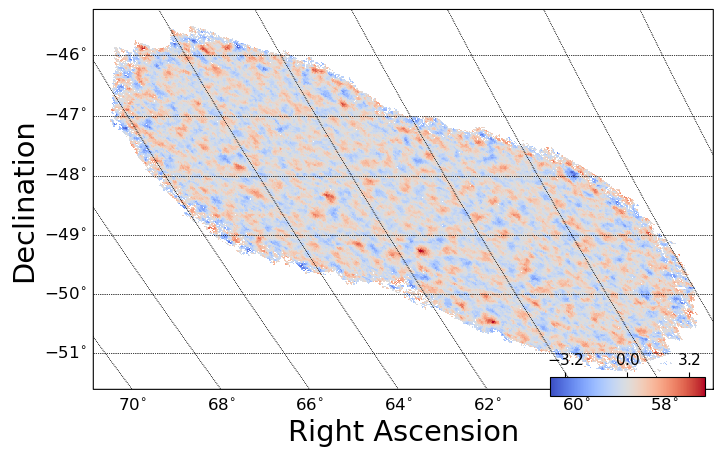

In [48]:
fig, ax = plt.subplots(figsize=(8, 5))
sp = skyproj.McBrydeSkyproj(ax=ax)
im, lon_raster, lat_raster, values_raster = sp.draw_hspmap(m_emode, cmap = cm.coolwarm, vmin=-4, vmax=4)
sp.draw_inset_colorbar(loc=4)
plt.show()